In [2]:
%load_ext autoreload
%autoreload 2

from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns
import pylab as pl
import pandas as pd
import numpy as np
import scipy as sp
from scipy import stats
from scipy.stats import invgauss
from sklearn.model_selection import KFold
from typing import NamedTuple
import yaml
import shelve

from caa_model.config import *
from caa_model.utils.get_yaml_data import ERStruct, RTConf, reformat_revised_data
from caa_model.models.base_model import BaseDDM
from caa_model.config import EPS
from caa_model.utils.multinomial_funcs import multinom_loglike

## Setup

In [4]:
caa_cfg = CAAConfig(
    delta_t=0.025,
    nr_ssteps=8192,
    nr_samples=10000,
    max_t=10.0,
)

db = shelve.open("data/neha_data_revised.yml.dat", "r")
data_group = db["empirical_results"]
db.close()

db = shelve.open("data/mengxue_data.yml.dat", "r")
data_subject = db["empirical_results"]
db.close()

def get_subject_data(full_data, subject_id):
    subject_id = str(subject_id).strip()

    # Order must match ERStruct: ["know_hit", "rem_hit", "know_fa", "rem_fa", "CR", "miss"]
    categories = ["know_hit", "rem_hit", "know_fa", "rem_fa", "CR", "miss"]
    filtered_cats = []

    for category in categories:
        cat_data = getattr(full_data, category)
        mask = cat_data.subj == subject_id

        filtered_cat = RTConf(
            rt=cat_data.rt[mask],
            conf=cat_data.conf[mask],
            target=cat_data.target[mask],
            subj=cat_data.subj[mask],
        )
        filtered_cats.append(filtered_cat)

    # Returning top-level ERStruct makes it fully picklable for parallel workers
    return ERStruct(*filtered_cats)

# Dynamically grab unique subjects
subject_ids = np.unique(data_subject.rem_hit.subj)
print(f"Found {len(subject_ids)} subjects to fit.")

Found 4 subjects to fit.


## RT Aggregated

### Setup

In [5]:
# --- 3. SATURATED NLL FLOOR LOGIC ---
def get_saturated_qmpe_nll(rts_old, rts_new):
    n_old = len(rts_old)
    n_new = len(rts_new)
    N = n_old + n_new
    if N == 0:
        return 0.0

    props = np.array([0.1, 0.2, 0.2, 0.2, 0.2, 0.1])
    x_old = n_old * props
    x_new = n_new * props
    x = np.concatenate([x_old, x_new])

    p = x / N
    return -multinom_loglike(x, N, p)

In [6]:
def generate_qq_plots(model, params, dataset, label="Subject 5"):
    """
    Generates Q-Q plots comparing Empirical RT quantiles to Model RT quantiles.
    """
    # 1. Setup Data and Quantiles
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt

    q_edges = np.array(model.config.quantiles)

    # 2. Get Model Predictions
    t_params, l_params = model.split_params(params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    # 3. Helper to compute Model Quantiles vs Empirical Quantiles
    def get_quantiles(rts, p_mass):
        if len(rts) == 0:
            return [], []

        # Empirical Quantiles
        emp_q = np.quantile(rts, q_edges)

        # Model Quantiles (Normalized CDF)
        cdf = np.cumsum(p_mass)
        if cdf[-1] == 0:
            return emp_q, np.zeros_like(emp_q)

        cdf_norm = cdf / cdf[-1]

        # Find the time points (t) where the model CDF crosses the target quantiles
        model_q_indices = np.searchsorted(cdf_norm, q_edges)
        # Clip to prevent index out of bounds if model flatlines
        model_q_indices = np.clip(model_q_indices, 0, len(t) - 1)
        model_q = t[model_q_indices]

        return emp_q, model_q

    # Calculate for all 4 categories
    emp_t_old, mod_t_old = get_quantiles(t_old_rts, p_old_t)
    emp_t_new, mod_t_new = get_quantiles(t_new_rts, p_new_t)
    emp_l_old, mod_l_old = get_quantiles(l_old_rts, p_old_l)
    emp_l_new, mod_l_new = get_quantiles(l_new_rts, p_new_l)

    # 4. Plotting
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Target Plot - Added [N=...]
    axes[0].plot(mod_t_old, emp_t_old, marker='o', color='blue', label=f'Old (Hits) [N={len(t_old_rts)}]')
    axes[0].plot(mod_t_new, emp_t_new, marker='o', color='black', label=f'New (Misses) [N={len(t_new_rts)}]')

    # Lure Plot - Added [N=...]
    axes[1].plot(mod_l_old, emp_l_old, marker='o', color='red', label=f'Old (FA) [N={len(l_old_rts)}]')
    axes[1].plot(mod_l_new, emp_l_new, marker='o', color='black', label=f'New (CR) [N={len(l_new_rts)}]')

    for ax, title in zip(axes, [f"{label} Targets Q-Q", f"{label} Lures Q-Q"]):
        ax.set_title(title)
        ax.set_xlabel("Model Predicted RT (sec)")
        ax.set_ylabel("Empirical Human RT (sec)")

        # Draw perfect fit identity line (y=x)
        lims = [
            np.min([ax.get_xlim(), ax.get_ylim()]),
            np.max([ax.get_xlim(), ax.get_ylim()]),
        ]
        ax.plot(lims, lims, 'k--', alpha=0.75, zorder=0, label="Perfect Fit (y=x)")
        ax.legend()

    plt.tight_layout()
    plt.show()

### Wiener Two Bound


 INITIALIZING ANALYSIS FOR AGGREGATED GROUP
Fitting 8-Parameter Boundary Physics...
differential_evolution step 1: f(x)= 2152.3732345779663
differential_evolution step 2: f(x)= 2152.3732345779663
differential_evolution step 3: f(x)= 2152.3732345779663
differential_evolution step 4: f(x)= 2152.3732345779663
differential_evolution step 5: f(x)= 2152.3732345779663
differential_evolution step 6: f(x)= 1379.9711278999075
differential_evolution step 7: f(x)= 1379.9711278999075
differential_evolution step 8: f(x)= 1379.9711278999075
differential_evolution step 9: f(x)= 1379.9711278999075
differential_evolution step 10: f(x)= 1328.6069831970399
differential_evolution step 11: f(x)= 1243.1186218640178
differential_evolution step 12: f(x)= 1088.2521579664826
differential_evolution step 13: f(x)= 845.9841439790871
differential_evolution step 14: f(x)= 845.9841439790871
differential_evolution step 15: f(x)= 717.1220620637323
differential_evolution step 16: f(x)= 304.4737251981369
differential_evo

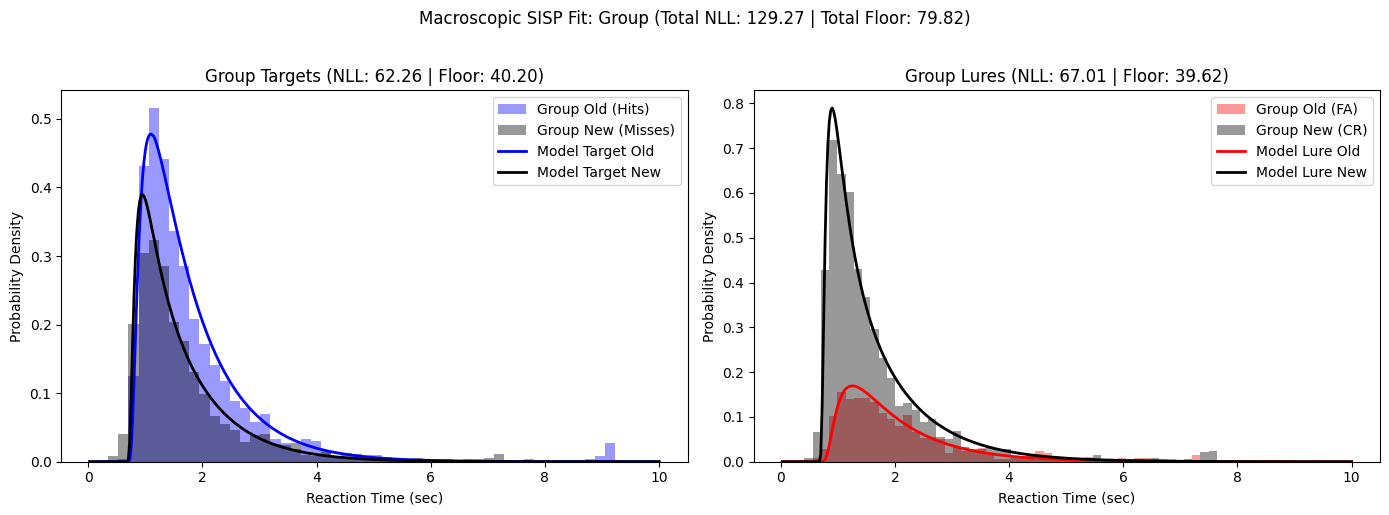

In [7]:
# --- 4. MACROSCOPIC SISP MODEL ---
class MacroscopicSISP(BaseDDM):
    """2-Choice Macroscopic limit test for a specific subject."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        d_t: float
        d_l: float
        tc_bound: float
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        return (mu_t, d_t, tc, z0_t, t0, True), (mu_l, d_l, tc, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_r, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            p_pos = tx[i][x >= bound[i]]
            p_old[i] = pl.sum(p_pos)
            p_new[i] = pl.sum(tx[i][x <= -bound[i]])
            tx[i] *= abs(x) < bound[i]

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0:
            return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0:
            return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- 5. EXECUTION WRAPPER ---
# --- 5. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    """Core fitting and plotting logic, abstracted to handle both Subjects and Group data."""
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = MacroscopicSISP(config=config)

    # Constrain z0 within valid boundaries (-0.8 to 0.8)
    param_bounds = (
        MacroscopicSISP.Params(mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0),
        MacroscopicSISP.Params(mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=0.8, z0_l=0.8, t0=1.0),
    )

    print(f"Fitting 8-Parameter Boundary Physics...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting with shared bin edges
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts))
    t_max = max(np.max(t_old_rts), np.max(t_new_rts))
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
    w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)

    axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")
    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts))
    l_max = max(np.max(l_old_rts), np.max(l_new_rts))
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
    w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)

    axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")
    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic SISP Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_group(data_group)

# Params(mu_t=np.float64(0.32415813577552266), mu_l=np.float64(-0.2534523877165345), d_t=np.float64(0.5487854042162205), d_l=np.float64(0.4878021395134811), tc_bound=np.float64(0.0003135076686020443), z0_t=np.float64(-0.1161266810772989), z0_l=np.float64(-0.2519533133916583), t0=np.float64(0.6731714926374323))

### Variable Drift Rate

In [ ]:
class DriftVariabilityMacroscopicSISP(BaseDDM):
    """2-Choice Macroscopic limit test with Intertrial Drift Variability (eta)."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        eta_t: float    # NEW: Target drift variability
        eta_l: float    # NEW: Lure drift variability
        d_t: float
        d_l: float
        tc_bound: float
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, eta_t, eta_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        return (mu_t, eta_t, d_t, tc, z0_t, t0, True), (mu_l, eta_l, d_l, tc, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_mean, eta, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        t = pl.linspace(delta_t, max_t, nr_tsteps)
        p_old_total = pl.zeros(pl.shape(t))
        p_new_total = pl.zeros(pl.shape(t))

        # 5-Node Gauss-Hermite Quadrature for standard normal distribution
        nodes = np.array([-2.85697001, -1.35562618,  0.0,  1.35562618,  2.85697001])
        weights = np.array([0.01125741,  0.22207592,  0.53333333,  0.22207592,  0.01125741])

        # If variance is virtually zero, skip the loop to save compute time
        if eta < 1e-4:
            drift_rates = [mu_mean]
            drift_weights = [1.0]
        else:
            drift_rates = mu_mean + (nodes * eta)
            drift_weights = weights

        sigma = pl.sqrt(2 * d * delta_t)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        # Evolve the probability cloud for each sample drift rate
        for mu_val, weight in zip(drift_rates, drift_weights):
            mu = mu_val * delta_t

            kernel = stats.norm.pdf(x, mu, sigma) * delta_s
            ft_kernel = self._fft(kernel)

            tx = pl.zeros((len(t), len(x)))
            p_old = pl.zeros(pl.shape(t))
            p_new = pl.zeros(pl.shape(t))

            tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

            for i in range(to_idx, len(t)):
                if i > to_idx:
                    tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

                p_pos = tx[i][x >= bound[i]]
                p_old[i] = pl.sum(p_pos)
                p_new[i] = pl.sum(tx[i][x <= -bound[i]])
                tx[i] *= abs(x) < bound[i]

            # Multiply by the quadrature weight and add to total
            p_old_total += p_old * weight
            p_new_total += p_new * weight

        return p_old_total, p_new_total, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0:
            return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0:
            return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- 5. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = DriftVariabilityMacroscopicSISP(config=config)

    # UPDATED: Added eta_t and eta_l to the param_bounds
    # (Allowing drift variability to stretch from 0.0 up to 2.0 standard deviations)
    param_bounds = (
        DriftVariabilityMacroscopicSISP.Params(mu_t=-2.0, mu_l=-2.0, eta_t=0.0, eta_l=0.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0),
        DriftVariabilityMacroscopicSISP.Params(mu_t=2.0, mu_l=2.0, eta_t=2.0, eta_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=0.8, z0_l=0.8, t0=1.0),
    )

    print(f"Fitting 10-Parameter Model (with Drift Variability)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting with shared bin edges
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts))
    t_max = max(np.max(t_old_rts), np.max(t_new_rts))
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
    w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)

    axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")
    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts))
    l_max = max(np.max(l_old_rts), np.max(l_new_rts))
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
    w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)

    axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")
    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic SISP Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_subject("7")

### Asymmetric Bounds, Variable Drift


 INITIALIZING ANALYSIS FOR SUBJECT: 1
Fitting 11-Parameter SISP (Asymmetric Urgency)...
differential_evolution step 1: f(x)= 1867.9364477993004
differential_evolution step 2: f(x)= 1097.9079447547906
differential_evolution step 3: f(x)= 1097.9079447547906
differential_evolution step 4: f(x)= 1097.9079447547906
differential_evolution step 5: f(x)= 1097.9079447547906
differential_evolution step 6: f(x)= 1078.7705717857257
differential_evolution step 7: f(x)= 796.5535393021478
differential_evolution step 8: f(x)= 796.5535393021478
differential_evolution step 9: f(x)= 580.0715638408269
differential_evolution step 10: f(x)= 580.0715638408269
differential_evolution step 11: f(x)= 580.0715638408269
differential_evolution step 12: f(x)= 406.72246676230907
differential_evolution step 13: f(x)= 406.72246676230907
differential_evolution step 14: f(x)= 302.2363876072641
differential_evolution step 15: f(x)= 207.70570607190575
differential_evolution step 16: f(x)= 207.70570607190575
differential_e

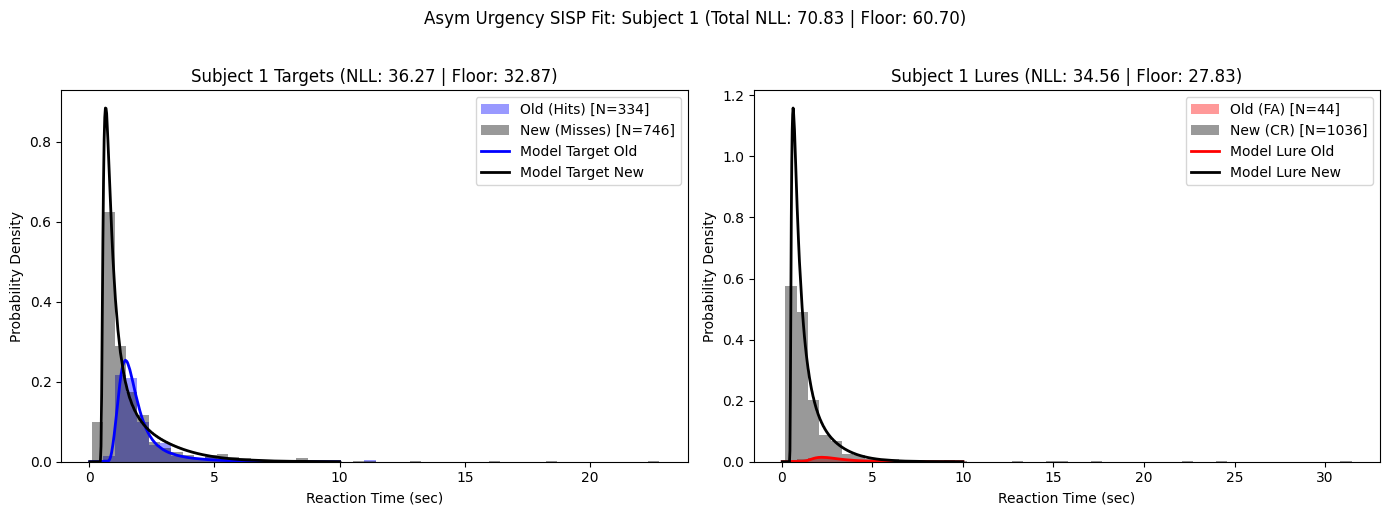


 INITIALIZING ANALYSIS FOR SUBJECT: 3
Fitting 11-Parameter SISP (Asymmetric Urgency)...
differential_evolution step 1: f(x)= 587.2596314720363
differential_evolution step 2: f(x)= 547.2399741315039
differential_evolution step 3: f(x)= 399.83382062199007
differential_evolution step 4: f(x)= 399.83382062199007
differential_evolution step 5: f(x)= 219.12832429287027
differential_evolution step 6: f(x)= 198.81653310171214
differential_evolution step 7: f(x)= 198.81653310171214
differential_evolution step 8: f(x)= 198.81653310171214
differential_evolution step 9: f(x)= 198.81653310171214
differential_evolution step 10: f(x)= 148.89664118102792
differential_evolution step 11: f(x)= 128.56502911563393
differential_evolution step 12: f(x)= 128.56502911563393
differential_evolution step 13: f(x)= 128.56502911563393
differential_evolution step 14: f(x)= 128.56502911563393
differential_evolution step 15: f(x)= 128.1318569860041
differential_evolution step 16: f(x)= 128.1318569860041
differential

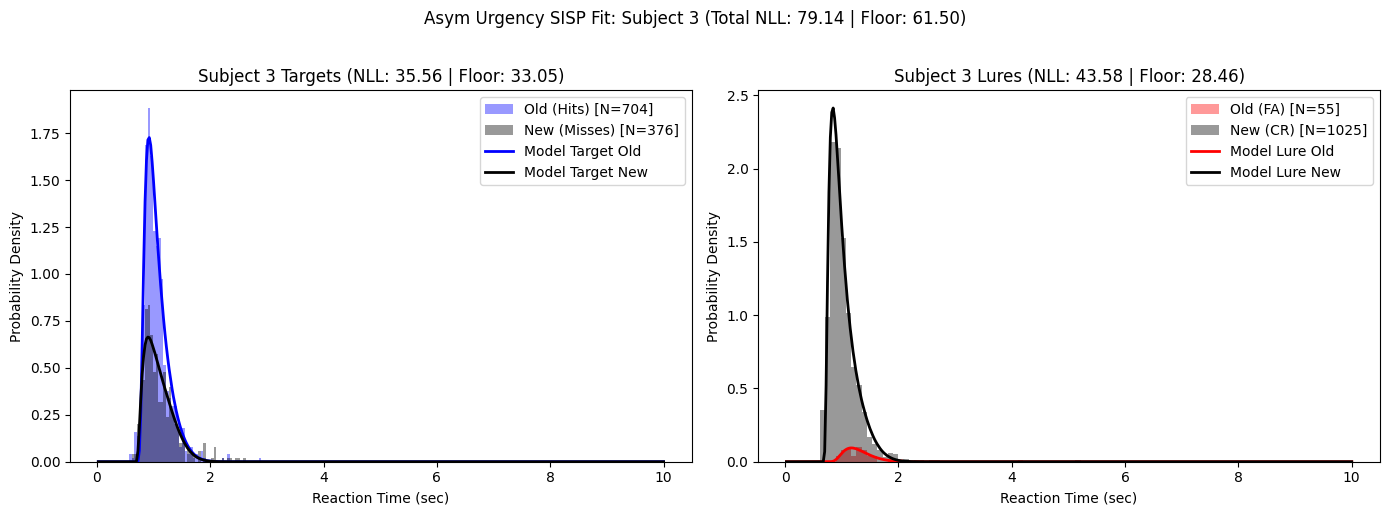


 INITIALIZING ANALYSIS FOR SUBJECT: 5
Fitting 11-Parameter SISP (Asymmetric Urgency)...
differential_evolution step 1: f(x)= 1118.3467686277372
differential_evolution step 2: f(x)= 1118.3467686277372
differential_evolution step 3: f(x)= 1118.3467686277372
differential_evolution step 4: f(x)= 1089.4786317166313
differential_evolution step 5: f(x)= 1017.5614339445005
differential_evolution step 6: f(x)= 857.2869328925294
differential_evolution step 7: f(x)= 655.7610538590598
differential_evolution step 8: f(x)= 655.7610538590598
differential_evolution step 9: f(x)= 503.97142916114217
differential_evolution step 10: f(x)= 503.97142916114217
differential_evolution step 11: f(x)= 491.360684367844
differential_evolution step 12: f(x)= 443.54681946698975
differential_evolution step 13: f(x)= 443.54681946698975
differential_evolution step 14: f(x)= 399.764720992358
differential_evolution step 15: f(x)= 399.764720992358
differential_evolution step 16: f(x)= 340.32588454620645
differential_evol

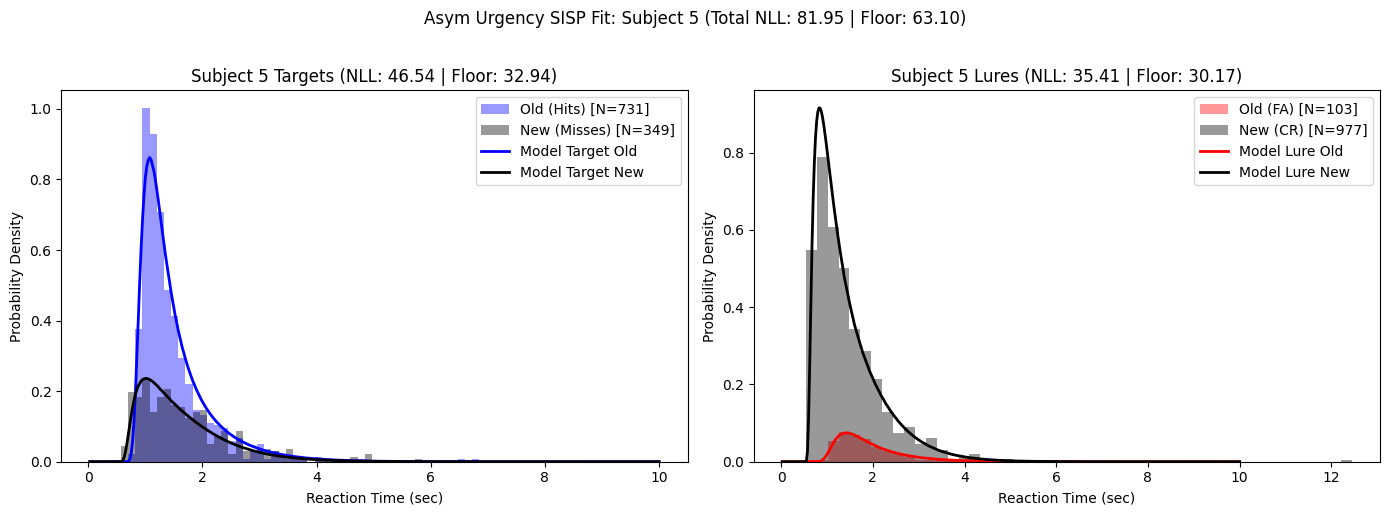


 INITIALIZING ANALYSIS FOR SUBJECT: 7
Fitting 11-Parameter SISP (Asymmetric Urgency)...
differential_evolution step 1: f(x)= 1172.6553381972358
differential_evolution step 2: f(x)= 1172.6553381972358
differential_evolution step 3: f(x)= 1152.9010209444841
differential_evolution step 4: f(x)= 712.0404500324448
differential_evolution step 5: f(x)= 710.2580361400428
differential_evolution step 6: f(x)= 698.9393676348345
differential_evolution step 7: f(x)= 517.5579968262782
differential_evolution step 8: f(x)= 408.58286182811025
differential_evolution step 9: f(x)= 408.58286182811025
differential_evolution step 10: f(x)= 408.58286182811025
differential_evolution step 11: f(x)= 352.4381924441823
differential_evolution step 12: f(x)= 352.4381924441823
differential_evolution step 13: f(x)= 352.4381924441823
differential_evolution step 14: f(x)= 352.4381924441823
differential_evolution step 15: f(x)= 321.41303437294505
differential_evolution step 16: f(x)= 258.30245261697405
differential_evo

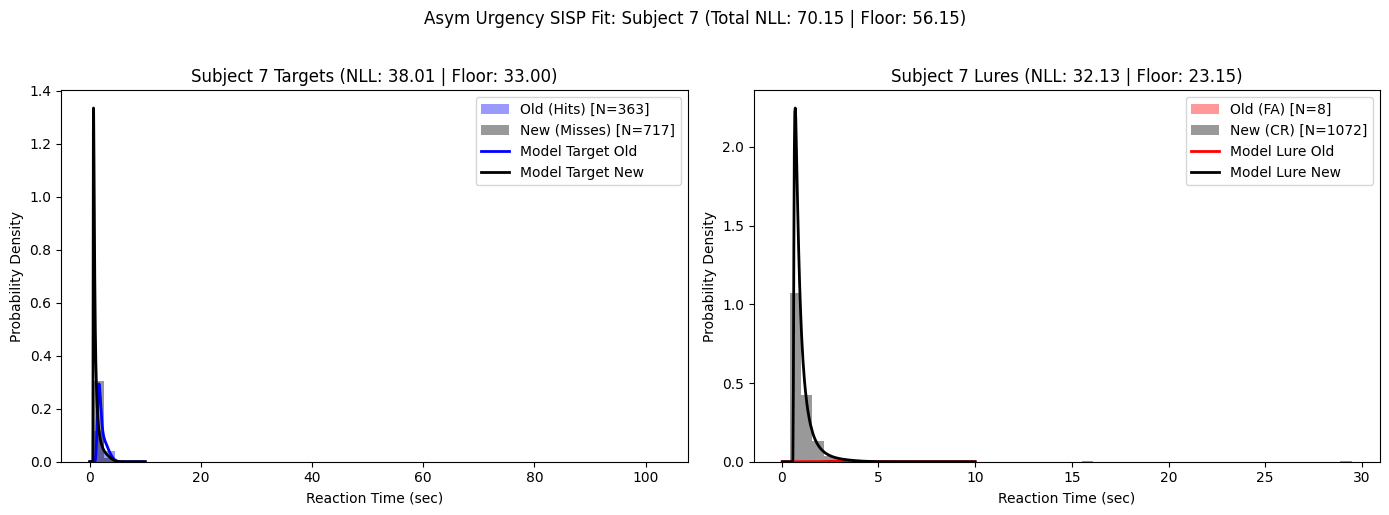


 INITIALIZING ANALYSIS FOR AGGREGATED GROUP
Fitting 11-Parameter SISP (Asymmetric Urgency)...
differential_evolution step 1: f(x)= 4501.596522640786
differential_evolution step 2: f(x)= 4501.596522640786
differential_evolution step 3: f(x)= 3285.9424029682323
differential_evolution step 4: f(x)= 1483.552961965821
differential_evolution step 5: f(x)= 1483.552961965821
differential_evolution step 6: f(x)= 1483.552961965821
differential_evolution step 7: f(x)= 1483.552961965821
differential_evolution step 8: f(x)= 1025.3122217234468
differential_evolution step 9: f(x)= 1025.3122217234468
differential_evolution step 10: f(x)= 1025.3122217234468
differential_evolution step 11: f(x)= 1025.3122217234468
differential_evolution step 12: f(x)= 1025.3122217234468
differential_evolution step 13: f(x)= 1025.3122217234468
differential_evolution step 14: f(x)= 859.0273997495915
differential_evolution step 15: f(x)= 456.96757505583446
differential_evolution step 16: f(x)= 456.96757505583446
different

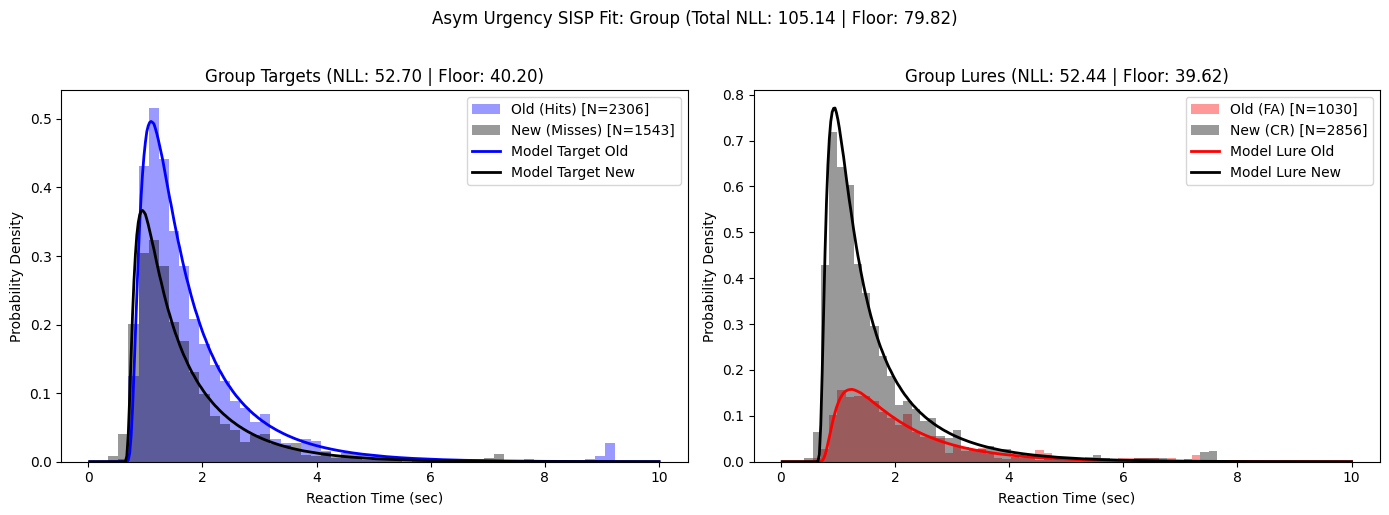

In [27]:
# --- 2. ASYMMETRIC URGENCY SISP (VARIABLE DRIFT) ---
class AsymBoundVarDriftMacroscopicSISP(BaseDDM):
    """
    11-Parameter Macroscopic SISP.
    Adds Variable Drift (eta) and Independent Collapse Rates (tc_old, tc_new).
    """
    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        eta_t: float
        eta_l: float
        d_t: float
        d_l: float
        tc_old: float  # <--- NEW: Upper Boundary Collapse Rate
        tc_new: float  # <--- NEW: Lower Boundary Collapse Rate
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, eta_t, eta_l, d_t, d_l, tc_old, tc_new, z0_t, z0_l, t0 = model_params
        return (mu_t, eta_t, d_t, tc_old, tc_new, z0_t, t0, True), \
               (mu_l, eta_l, d_l, tc_old, tc_new, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_mean, eta, d, tc_old, tc_new, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        t = pl.linspace(delta_t, max_t, nr_tsteps)
        p_old_total = pl.zeros(pl.shape(t))
        p_new_total = pl.zeros(pl.shape(t))

        # Standard 5-Node Gaussian Quadrature for variable drift
        z_nodes = np.array([-2.85697001, -1.35562618,  0.0,  1.35562618,  2.85697001])
        weights = np.array([0.01125741,  0.22207592,  0.53333333,  0.22207592,  0.01125741])

        if eta < 1e-4:
            drift_rates = [mu_mean]
            drift_weights = [1.0]
        else:
            drift_rates = mu_mean + (z_nodes * eta)
            drift_weights = weights

        sigma = pl.sqrt(2 * d * delta_t)
        to_idx = pl.argmin((t - t0) ** 2)

        # Independent Boundary Collapses
        bound_old = pl.exp(-tc_old * pl.clip(t - t0, 0, None))
        bound_new = pl.exp(-tc_new * pl.clip(t - t0, 0, None))

        space_lim = max(pl.max(bound_old), pl.max(bound_new)) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        for mu_val, weight in zip(drift_rates, drift_weights):
            mu = mu_val * delta_t

            kernel = stats.norm.pdf(x, mu, sigma) * delta_s
            ft_kernel = self._fft(kernel)

            tx = pl.zeros((len(t), len(x)))
            p_old = pl.zeros(pl.shape(t))
            p_new = pl.zeros(pl.shape(t))

            tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

            for i in range(to_idx, len(t)):
                if i > to_idx:
                    tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

                # Extract mass crossing the independent boundaries
                p_pos = tx[i][x >= bound_old[i]]
                p_old[i] = pl.sum(p_pos)
                p_new[i] = pl.sum(tx[i][x <= -bound_new[i]])

                # Zero out particles that crossed either boundary
                tx[i] *= (x < bound_old[i]) & (x > -bound_new[i])

            p_old_total += p_old * weight
            p_new_total += p_new * weight

        return p_old_total, p_new_total, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            # Firmly locked at theoretical 2% lapse
            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t, lapse_rate=0.02)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t, lapse_rate=0.02)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))


# --- 3. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis(f"Subject {subject_id}", subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = AsymBoundVarDriftMacroscopicSISP(config=config)

    # 11 Parameters (tc_old, tc_new replace tc_bound)
    param_bounds = (
        AsymBoundVarDriftMacroscopicSISP.Params(
            mu_t=-2.0, mu_l=-2.0, eta_t=0.0, eta_l=0.0,
            d_t=EPS, d_l=EPS, tc_old=0.0, tc_new=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0
        ),
        AsymBoundVarDriftMacroscopicSISP.Params(
            mu_t=2.0, mu_l=2.0, eta_t=2.0, eta_l=2.0,
            d_t=2.0, d_l=2.0, tc_old=3.0, tc_new=3.0, z0_t=0.8, z0_l=0.8, t0=1.0
        )
    )

    print(f"Fitting 11-Parameter SISP (Asymmetric Urgency)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Upper Bound Collapse (tc_old): {best_params.tc_old:.2f}")
    print(f" Lower Bound Collapse (tc_new): {best_params.tc_new:.2f}")
    print(f" Absolute NLL Floor:            {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit:          {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:             {eval_result.nll - total_floor:.2f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"Old (Hits) [N={len(t_old_rts)}]")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"New (Misses) [N={len(t_new_rts)}]")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"Old (FA) [N={len(l_old_rts)}]")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"New (CR) [N={len(l_new_rts)}]")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Asym Urgency SISP Fit: {label} (Total NLL: {eval_result.nll:.2f} | Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    # You can loop this across subjects or run the group directly
    subjects = ["1", "3", "5", "7"]
    results = {}
    for sub in subjects:
        results[sub] = analyze_subject(sub)
    results["group"] = analyze_group(data_group)

### DIDP


 INITIALIZING ANALYSIS FOR SUBJECT: 1
Fitting 9-Parameter DIDP Race Model...
differential_evolution step 1: f(x)= 2101.1025021330424
differential_evolution step 2: f(x)= 984.4246075469496
differential_evolution step 3: f(x)= 984.4246075469496
differential_evolution step 4: f(x)= 984.4246075469496
differential_evolution step 5: f(x)= 895.1526168920172
differential_evolution step 6: f(x)= 868.4218049594597
differential_evolution step 7: f(x)= 664.8442215708524
differential_evolution step 8: f(x)= 664.8442215708524
differential_evolution step 9: f(x)= 648.9250215540533
differential_evolution step 10: f(x)= 648.9250215540533
differential_evolution step 11: f(x)= 648.9250215540533
differential_evolution step 12: f(x)= 540.3054745012428
differential_evolution step 13: f(x)= 466.6599573474318
differential_evolution step 14: f(x)= 310.0497385011604
differential_evolution step 15: f(x)= 310.0497385011604
differential_evolution step 16: f(x)= 310.0497385011604
differential_evolution step 17: f(

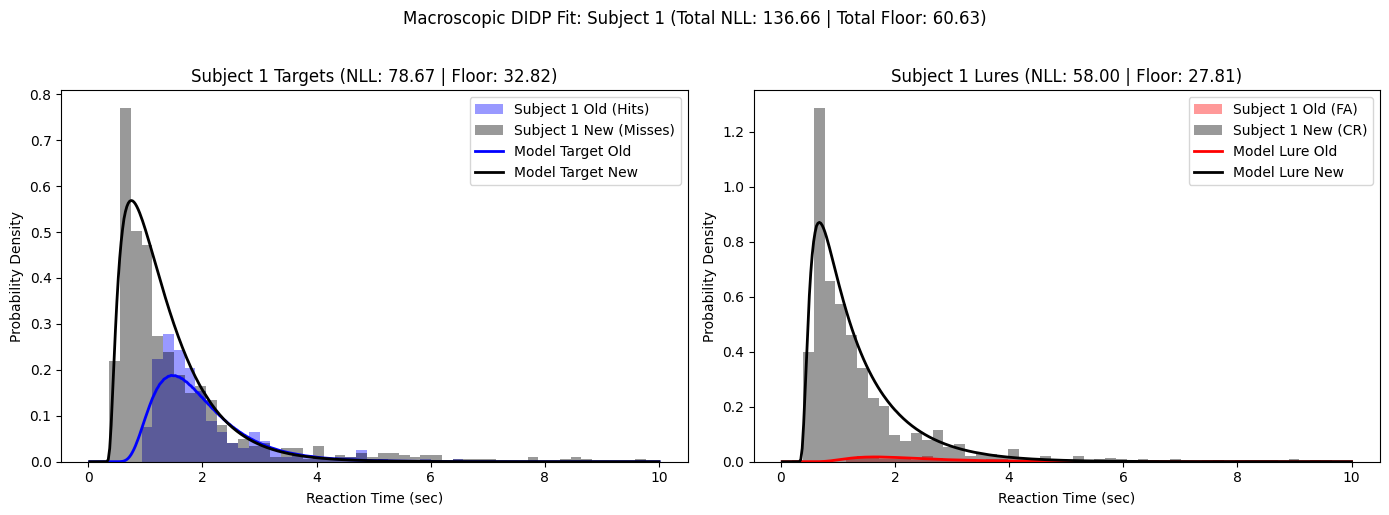

In [33]:
# --- 4. MACROSCOPIC DIDP MODEL (INDEPENDENT RACE) ---
class MacroscopicDIDP(BaseDDM):
    """Independent Race Model (DIDP) for Macroscopic 2-Choice Data."""

    class Params(NamedTuple):
        mu_old_t: float
        mu_new_t: float
        mu_old_l: float
        mu_new_l: float
        d_old: float
        d_new: float
        tc_old: float
        tc_new: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_old_t, mu_new_t, mu_old_l, mu_new_l, d_old, d_new, tc_old, tc_new, t0 = model_params
        return (mu_old_t, mu_new_t, d_old, d_new, tc_old, tc_new, t0), \
               (mu_old_l, mu_new_l, d_old, d_new, tc_old, tc_new, t0)

    def _run_single_accumulator(self, mu_mean, d, tc_bound, t0):
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        t = pl.linspace(delta_t, max_t, nr_tsteps)
        p_hit = pl.zeros(pl.shape(t))

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_mean * delta_t
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        tx[to_idx] = stats.norm.pdf(x, 0, sigma) * delta_s  # Start at 0

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            p_pos = tx[i][x >= bound[i]]
            p_hit[i] = pl.sum(p_pos)
            tx[i] *= (x < bound[i])

        return p_hit, t

    def predicted_proportions(self, params):
        mu_old, mu_new, d_old, d_new, tc_old, tc_new, t0 = params

        # Race the two accumulators independently
        p_hit_old, t = self._run_single_accumulator(mu_old, d_old, tc_old, t0)
        p_hit_new, _ = self._run_single_accumulator(mu_new, d_new, tc_new, t0)

        cdf_old = pl.cumsum(p_hit_old)
        cdf_new = pl.cumsum(p_hit_new)

        # Prob of responding 'Old' is prob Old crosses * Prob New hasn't crossed yet
        p_old_final = p_hit_old * (1.0 - cdf_new)
        p_new_final = p_hit_new * (1.0 - cdf_old)

        return p_old_final, p_new_final, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- 5. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    # Apply Outlier Filter
    filtered_data = ERStruct(*[
        RTConf(rt=cat.rt[(cat.rt > 0.2) & (cat.rt < 9.9)],
               conf=cat.conf[(cat.rt > 0.2) & (cat.rt < 9.9)],
               target=cat.target[(cat.rt > 0.2) & (cat.rt < 9.9)],
               subj=cat.subj[(cat.rt > 0.2) & (cat.rt < 9.9)])
        for cat in subj_data
    ])
    return _run_analysis("Subject " + subject_id, filtered_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    # Apply Outlier Filter
    filtered_data = ERStruct(*[
        RTConf(rt=cat.rt[(cat.rt > 0.2) & (cat.rt < 9.9)],
               conf=cat.conf[(cat.rt > 0.2) & (cat.rt < 9.9)],
               target=cat.target[(cat.rt > 0.2) & (cat.rt < 9.9)],
               subj=cat.subj[(cat.rt > 0.2) & (cat.rt < 9.9)])
        for cat in group_data
    ])
    return _run_analysis("Group", filtered_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = MacroscopicDIDP(config=config)

    param_bounds = (
        MacroscopicDIDP.Params(mu_old_t=0.0, mu_new_t=0.0, mu_old_l=0.0, mu_new_l=0.0, d_old=EPS, d_new=EPS, tc_old=0.0, tc_new=0.0, t0=0.0),
        MacroscopicDIDP.Params(mu_old_t=3.0, mu_new_t=3.0, mu_old_l=3.0, mu_new_l=3.0, d_old=2.0, d_new=2.0, tc_old=2.0, tc_new=2.0, t0=1.0)
    )

    print(f"Fitting 9-Parameter DIDP Race Model...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic DIDP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic DIDP Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_subject("1")

### Lapse Rate


 INITIALIZING ANALYSIS FOR SUBJECT: 7
Fitting 9-Parameter SISP (Free Lapse Rate)...


differential_evolution step 1: f(x)= 722.6175318012993
differential_evolution step 2: f(x)= 504.30185754806917
differential_evolution step 3: f(x)= 504.30185754806917
differential_evolution step 4: f(x)= 504.30185754806917
differential_evolution step 5: f(x)= 504.30185754806917
differential_evolution step 6: f(x)= 504.30185754806917
differential_evolution step 7: f(x)= 504.30185754806917
differential_evolution step 8: f(x)= 504.30185754806917
differential_evolution step 9: f(x)= 504.30185754806917
differential_evolution step 10: f(x)= 413.3205234040838
differential_evolution step 11: f(x)= 367.66003416527974
differential_evolution step 12: f(x)= 331.59059446421907
differential_evolution step 13: f(x)= 315.6833729323673
differential_evolution step 14: f(x)= 231.87431215500396
differential_evolution step 15: f(x)= 224.31017095593234
differential_evolution step 16: f(x)= 209.8615547057516
differential_evolution step 17: f(x)= 209.8615547057516
differential_evolution step 18: f(x)= 209.861

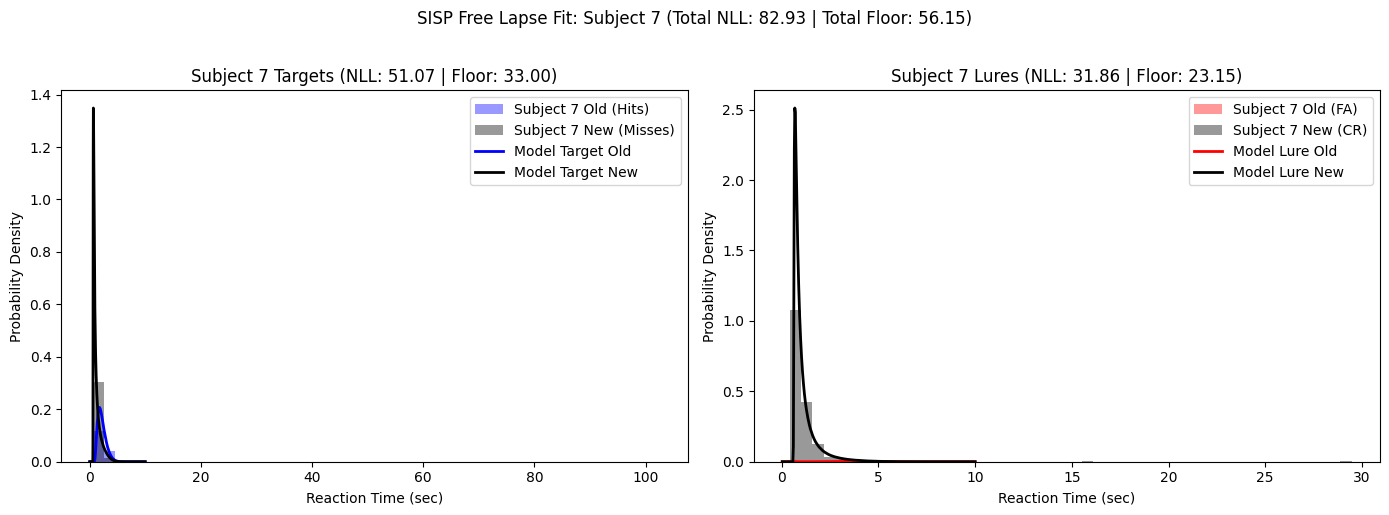

In [44]:
# --- MACROSCOPIC SISP (WITH FREE LAPSE RATE) ---
class FreeLapseMacroscopicSISP(BaseDDM):
    """Original SISP Model with Lapse Rate as a Free Parameter."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        d_t: float
        d_l: float
        tc_bound: float
        z0_t: float
        z0_l: float
        t0: float
        lapse_rate: float  # <--- NEW: Free Parameter for Outliers

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, z0_t, z0_l, t0, lapse = model_params
        return (mu_t, d_t, tc, z0_t, t0, lapse, True), (mu_l, d_l, tc, z0_l, t0, lapse, False)

    def predicted_proportions(self, params):
        mu_r, d, tc_bound, z0, t0, lapse, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            p_pos = tx[i][x >= bound[i]]
            p_old[i] = pl.sum(p_pos)
            p_new[i] = pl.sum(tx[i][x <= -bound[i]])
            tx[i] *= abs(x) < bound[i]

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)
            # The lapse rate is now extracted from the params
            lapse_rate = t_params[5]

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            # Pass the dynamically fitted lapse rate into QMPE
            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t, lapse_rate)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t, lapse_rate)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        # Uses the specific lapse rate chosen by the optimizer for this iteration
        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = FreeLapseMacroscopicSISP(config=config)

    # Added lapse_rate bounded between 0% and 10%
    param_bounds = (
        FreeLapseMacroscopicSISP.Params(mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0, lapse_rate=0.0),
        FreeLapseMacroscopicSISP.Params(mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=0.8, z0_l=0.8, t0=1.0, lapse_rate=0.10)
    )

    print(f"Fitting 9-Parameter SISP (Free Lapse Rate)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    # Pass the fitted lapse rate for final evaluation
    fitted_lapse = t_params[5]
    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t, fitted_lapse)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t, fitted_lapse)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Fitted Lapse Rate:    {fitted_lapse * 100:.2f}%")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting (same logic as before)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"SISP Free Lapse Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_subject("7")

### Asymmetric Boundaries


 INITIALIZING ANALYSIS FOR SUBJECT: 1
Fitting 9-Parameter SISP (Asymmetric Boundaries)...


differential_evolution step 1: f(x)= 1403.5830711241206
differential_evolution step 2: f(x)= 794.1334417707867
differential_evolution step 3: f(x)= 794.1334417707867
differential_evolution step 4: f(x)= 794.1334417707867
differential_evolution step 5: f(x)= 588.4376286392558
differential_evolution step 6: f(x)= 588.4376286392558
differential_evolution step 7: f(x)= 588.4376286392558
differential_evolution step 8: f(x)= 588.4376286392558
differential_evolution step 9: f(x)= 588.4376286392558
differential_evolution step 10: f(x)= 588.4376286392558
differential_evolution step 11: f(x)= 588.4376286392558
differential_evolution step 12: f(x)= 588.4376286392558
differential_evolution step 13: f(x)= 403.62771272272266
differential_evolution step 14: f(x)= 403.62771272272266
differential_evolution step 15: f(x)= 347.7993475323083
differential_evolution step 16: f(x)= 347.7993475323083
differential_evolution step 17: f(x)= 347.7993475323083
differential_evolution step 18: f(x)= 287.304880905498

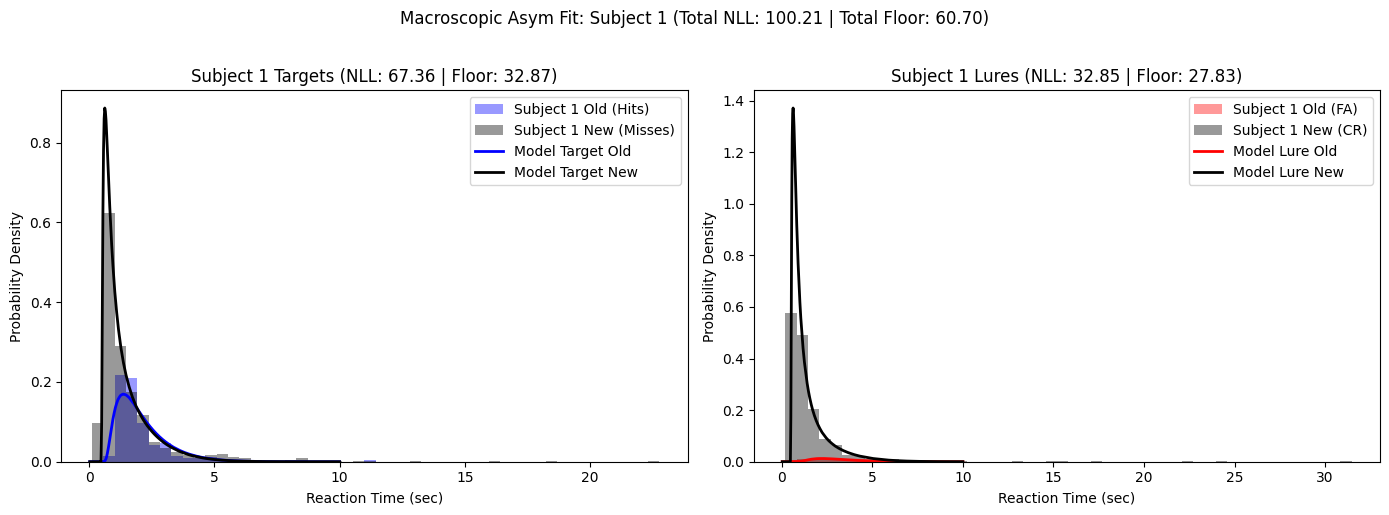

In [50]:
# --- MACROSCOPIC SISP (ASYMMETRIC BOUNDARIES ONLY) ---
class MacroscopicSISP_AsymBound(BaseDDM):
    """Macroscopic SISP with Asymmetric Boundary Distances (Fixed 2% Lapse Rate)."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        d_t: float
        d_l: float
        tc_bound: float
        bound_asym: float  # <--- NEW: Multiplier for the lower (New) boundary
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, asym, z0_t, z0_l, t0 = model_params
        return (mu_t, d_t, tc, asym, z0_t, t0, True), (mu_l, d_l, tc, asym, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_r, d, tc_bound, bound_asym, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        # Base symmetric boundary collapse
        base_bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))

        # Apply the asymmetry multiplier to the New boundary
        upper_bound = base_bound
        lower_bound = -base_bound * bound_asym

        # Space limits must stretch to accommodate whichever boundary is larger
        space_lim = max(pl.max(upper_bound), pl.max(abs(lower_bound))) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            # Extract mass crossing the asymmetric boundaries
            p_pos = tx[i][x >= upper_bound[i]]
            p_old[i] = pl.sum(p_pos)
            p_new[i] = pl.sum(tx[i][x <= lower_bound[i]])

            # Zero out particles that crossed either boundary
            tx[i] *= (x < upper_bound[i]) & (x > lower_bound[i])

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            # Uses the default 0.02 (2%) lapse rate locked into the function signature
            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = MacroscopicSISP_AsymBound(config=config)

    # 9 Parameters (Asymmetry added, Lapse Rate removed)
    param_bounds = (
        MacroscopicSISP_AsymBound.Params(mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, bound_asym=0.5, z0_t=-0.8, z0_l=-0.8, t0=0.0),
        MacroscopicSISP_AsymBound.Params(mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, bound_asym=3.0, z0_t=0.8, z0_l=0.8, t0=1.0)
    )

    print(f"Fitting 9-Parameter SISP (Asymmetric Boundaries)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Boundary Asymmetry:   {best_params.bound_asym:.2f}x")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic Asym Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_subject("1")

### Delayed Boundary Collapse


 INITIALIZING ANALYSIS FOR SUBJECT: 3
Fitting 9-Parameter SISP (Delayed Boundary Collapse)...
differential_evolution step 1: f(x)= 306.2883191165033
differential_evolution step 2: f(x)= 306.2883191165033
differential_evolution step 3: f(x)= 229.75404065157863
differential_evolution step 4: f(x)= 229.75404065157863
differential_evolution step 5: f(x)= 229.75404065157863
differential_evolution step 6: f(x)= 229.75404065157863
differential_evolution step 7: f(x)= 229.75404065157863
differential_evolution step 8: f(x)= 229.75404065157863
differential_evolution step 9: f(x)= 229.75404065157863
differential_evolution step 10: f(x)= 225.72102449104887
differential_evolution step 11: f(x)= 202.0444979727513
differential_evolution step 12: f(x)= 202.0444979727513
differential_evolution step 13: f(x)= 179.9669000765998
differential_evolution step 14: f(x)= 178.2289942916541
differential_evolution step 15: f(x)= 178.2289942916541
differential_evolution step 16: f(x)= 171.0278595466516
differenti

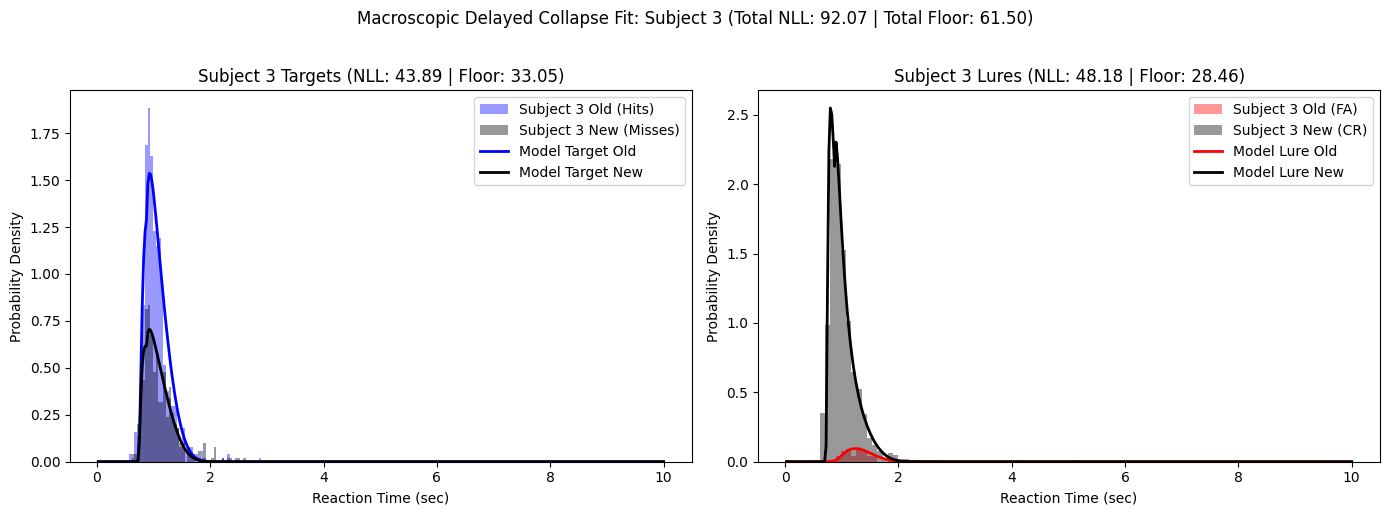

In [55]:
# --- MACROSCOPIC SISP (DELAYED COLLAPSE) ---
class DelayedCollapseMacroscopicSISP(BaseDDM):
    """Macroscopic SISP with a delayed onset for boundary collapse."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        d_t: float
        d_l: float
        tc_bound: float
        t_delay: float  # <--- NEW: Delay in seconds before boundary starts collapsing
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, delay, z0_t, z0_l, t0 = model_params
        return (mu_t, d_t, tc, delay, z0_t, t0, True), (mu_l, d_l, tc, delay, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_r, d, tc_bound, t_delay, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        # The boundary stays perfectly flat until (t0 + t_delay)
        bound = pl.exp(-tc_bound * pl.clip(t - (t0 + t_delay), 0, None))

        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            p_pos = tx[i][x >= bound[i]]
            p_old[i] = pl.sum(p_pos)
            p_new[i] = pl.sum(tx[i][x <= -bound[i]])
            tx[i] *= abs(x) < bound[i]

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        # Uses the theoretically fixed 2% lapse rate
        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))


# --- EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis("Subject " + subject_id, subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = DelayedCollapseMacroscopicSISP(config=config)

    # 9 Parameters (added t_delay bounded up to 5.0 seconds)
    param_bounds = (
        DelayedCollapseMacroscopicSISP.Params(mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, t_delay=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0),
        DelayedCollapseMacroscopicSISP.Params(mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=3.0, t_delay=5.0, z0_t=0.8, z0_l=0.8, t0=1.0)
    )

    print(f"Fitting 9-Parameter SISP (Delayed Boundary Collapse)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Collapse Delay Time:  {best_params.t_delay:.2f} seconds")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Macroscopic Delayed Collapse Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    eval_result = analyze_subject("3")

### Inv Gauss


 INITIALIZING ANALYSIS FOR SUBJECT: 7
Fitting Independent Inverse Gaussian Distributions...

--- RESULTS FOR Subject 7 ---
 Absolute NLL Floor:    56.15 (Target: 33.00, Lure: 23.15)
 Independent InvGauss:  169.47 (Target: 97.07, Lure: 72.40)
 Total NLL Penalty:     113.33


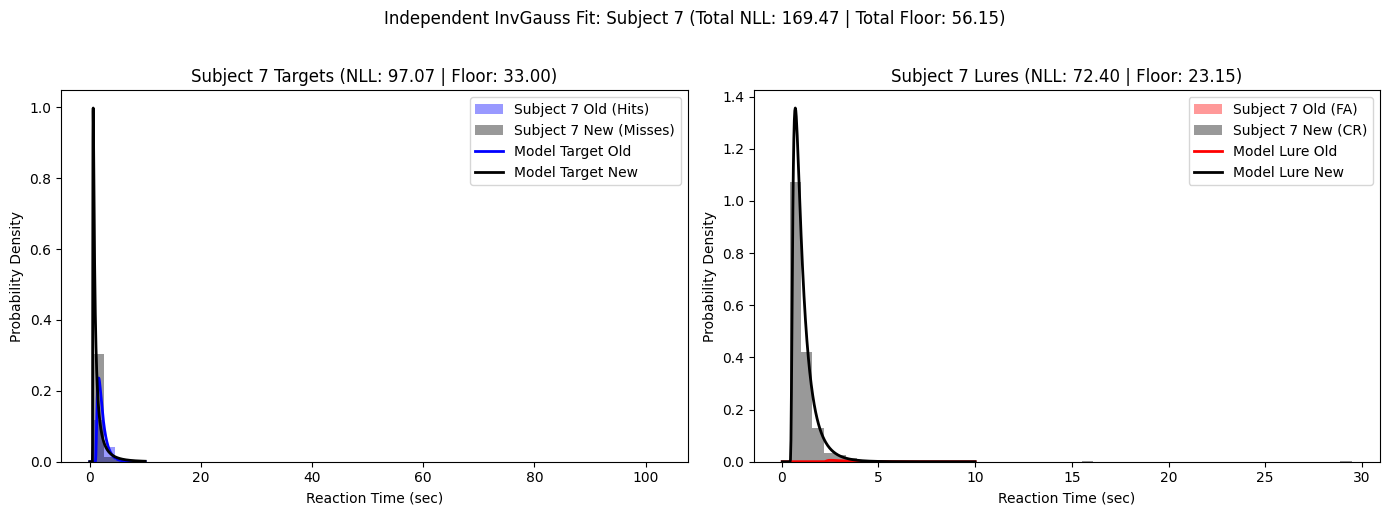

In [12]:
# --- 4. INDEPENDENT INVERSE GAUSSIAN MODEL ---
class InvGaussMacroscopicSISP(BaseDDM):
    """
    Fits independent Inverse Gaussian distributions to each of the 4 response categories:
    Target Old (Hits), Target New (Misses), Lure Old (False Alarms), Lure New (Correct Rejections).
    """

    class Params(NamedTuple):
        # Target Old (Hits)
        mu_t_old: float
        scale_t_old: float
        t0_t_old: float
        # Target New (Misses)
        mu_t_new: float
        scale_t_new: float
        t0_t_new: float
        p_t_old: float       # Choice proportion for Old given Target

        # Lure Old (False Alarms)
        mu_l_old: float
        scale_l_old: float
        t0_l_old: float
        # Lure New (Correct Rejections)
        mu_l_new: float
        scale_l_new: float
        t0_l_new: float
        p_l_old: float       # Choice proportion for Old given Lure

    @staticmethod
    def split_params(model_params):
        """Splits the 14 parameters into target and lure subsets."""
        p = model_params
        target_params = (p.mu_t_old, p.scale_t_old, p.t0_t_old, p.mu_t_new, p.scale_t_new, p.t0_t_new, p.p_t_old)
        lure_params = (p.mu_l_old, p.scale_l_old, p.t0_l_old, p.mu_l_new, p.scale_l_new, p.t0_l_new, p.p_l_old)
        return target_params, lure_params

    def predicted_proportions(self, params):
        """
        Computes discrete predicted probability mass across time grid t
        for Old and New responses using the fitted Inverse Gaussian distributions.
        """
        mu_old, scale_old, t0_old, mu_new, scale_new, t0_new, p_old_choice = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        t = pl.linspace(delta_t, max_t, nr_tsteps)

        # Evaluate continuous Inverse Gaussian density
        pdf_old = invgauss.pdf(t, mu_old, loc=t0_old, scale=scale_old)
        pdf_new = invgauss.pdf(t, mu_new, loc=t0_new, scale=scale_new)

        # Normalize density over finite grid
        sum_old = pl.sum(pdf_old * delta_t)
        sum_new = pl.sum(pdf_new * delta_t)
        if sum_old > 0:
            pdf_old /= sum_old
        if sum_new > 0:
            pdf_new /= sum_new

        # Scale by choice probability mass
        p_old = p_old_choice * pdf_old * delta_t
        p_new = (1.0 - p_old_choice) * pdf_new * delta_t

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0:
            return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0:
            return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

    def _fit_single_distribution(self, rts):
        """Fits an Inverse Gaussian to a single 1D reaction time array."""
        if len(rts) == 0:
            return 1.0, 1.0, 0.2
        try:
            # Maximum-likelihood fit via scipy.stats
            shape, loc, scale = invgauss.fit(rts)
            # Guarantee shift (t0) is strictly prior to earliest RT
            min_rt = np.min(rts)
            if loc >= min_rt:
                loc = min_rt * 0.8
            return shape, scale, loc
        except Exception:
            return 1.0, float(np.std(rts)), float(np.min(rts) * 0.8)

    def fit(self, param_bounds=None, data=None, nr_workers=1, method="qmpe", use_chisq=False):
        """
        Fits each of the 4 distributions independently directly to the empirical RTs,
        bypassing the slow 14D joint search while guaranteeing decoupled parameter recovery.
        """
        t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
        t_new_rts = data.miss.rt
        l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
        l_new_rts = data.CR.rt

        # Compute empirical choice proportions
        n_t_old = len(t_old_rts)
        n_t_new = len(t_new_rts)
        n_l_old = len(l_old_rts)
        n_l_new = len(l_new_rts)

        p_t_old = n_t_old / (n_t_old + n_t_new) if (n_t_old + n_t_new) > 0 else 0.5
        p_l_old = n_l_old / (n_l_old + n_l_new) if (n_l_old + n_l_new) > 0 else 0.5

        # Fit each distribution independently
        mu_t_old, scale_t_old, t0_t_old = self._fit_single_distribution(t_old_rts)
        mu_t_new, scale_t_new, t0_t_new = self._fit_single_distribution(t_new_rts)
        mu_l_old, scale_l_old, t0_l_old = self._fit_single_distribution(l_old_rts)
        mu_l_new, scale_l_new, t0_l_new = self._fit_single_distribution(l_new_rts)

        return self.Params(
            mu_t_old=mu_t_old, scale_t_old=scale_t_old, t0_t_old=t0_t_old,
            mu_t_new=mu_t_new, scale_t_new=scale_t_new, t0_t_new=t0_t_new,
            p_t_old=p_t_old,
            mu_l_old=mu_l_old, scale_l_old=scale_l_old, t0_l_old=t0_l_old,
            mu_l_new=mu_l_new, scale_l_new=scale_l_new, t0_l_new=t0_l_new,
            p_l_old=p_l_old
        )

# --- 5. EXECUTION WRAPPER ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_invgauss_analysis("Subject " + subject_id, subj_data, config)


def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_invgauss_analysis("Group", group_data, config)


def _run_invgauss_analysis(label, dataset, config):
    """Core fitting and plotting logic for Inverse Gaussian model."""
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = InvGaussMacroscopicSISP(config=config)

    print(f"Fitting Independent Inverse Gaussian Distributions...")
    best_params = model.fit(data=dataset, method="qmpe")
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:    {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Independent InvGauss:  {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:     {eval_result.nll - total_floor:.2f}")

    # Plotting with shared bin edges
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    # Target Plots
    t_min = min(np.min(t_old_rts), np.min(t_new_rts))
    t_max = max(np.max(t_old_rts), np.max(t_new_rts))
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
    w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)

    axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"{label} Old (Hits)")
    axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"{label} New (Misses)")
    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    # Lure Plots
    l_min = min(np.min(l_old_rts), np.min(l_new_rts))
    l_max = max(np.max(l_old_rts), np.max(l_new_rts))
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
    w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)

    axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"{label} Old (FA)")
    axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"{label} New (CR)")
    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Independent InvGauss Fit: {label} (Total NLL: {eval_result.nll:.2f} | Total Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    # You can now call analyze_group directly with your loaded `data_group` struct:
    eval_result = analyze_subject("7")


# Params(mu_t_old=np.float64(0.648521731974389), scale_t_old=np.float64(2.083294832867084), t0_t_old=np.float64(0.5306425813005251), mu_t_new=np.float64(0.4402849927912569), scale_t_new=np.float64(3.3940893045025335), t0_t_new=np.float64(0.24832033737394574), p_t_old=0.5991166536762795, mu_l_old=np.float64(0.6043589531645326), scale_l_old=np.float64(2.9224184854451076), t0_l_old=np.float64(0.45917189142994075), mu_l_new=np.float64(0.5347203488194325), scale_l_new=np.float64(2.414839959447282), t0_l_new=np.float64(0.36556034192821685), p_l_old=0.26505404014410705)

### Linear Bound, Skew Drift Variability

In [ ]:
# --- 2. MACROSCOPIC SISP (LINEAR BOUNDARY & SKEWED DRIFT) ---
class LinearSkewMacroscopicSISP(BaseDDM):
    """SISP Model replacing exponential collapse with Linear Deadline,
       and symmetric Gaussian drift with a Skewed Lognormal drift."""

    class Params(NamedTuple):
        mu_t: float
        mu_l: float
        eta_t: float
        eta_l: float
        skew_t: float  # <--- NEW: Skewness of target drift (-2.0 to 2.0)
        skew_l: float  # <--- NEW: Skewness of lure drift (-2.0 to 2.0)
        d_t: float
        d_l: float
        tc_bound: float # <--- NOW: Linear collapse slope
        z0_t: float
        z0_l: float
        t0: float

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, eta_t, eta_l, skew_t, skew_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        return (mu_t, eta_t, skew_t, d_t, tc, z0_t, t0, True), \
               (mu_l, eta_l, skew_l, d_l, tc, z0_l, t0, False)

    def predicted_proportions(self, params):
        mu_mean, eta, skew, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        t = pl.linspace(delta_t, max_t, nr_tsteps)
        p_old_total = pl.zeros(pl.shape(t))
        p_new_total = pl.zeros(pl.shape(t))

        # Standard 5-Node Gaussian Quadrature
        z_nodes = np.array([-2.85697001, -1.35562618,  0.0,  1.35562618,  2.85697001])
        weights = np.array([0.01125741,  0.22207592,  0.53333333,  0.22207592,  0.01125741])

        # Apply Lognormal Skewing (Mean=0, Variance=1 transformation)
        if abs(skew) < 1e-4:
            v_nodes = z_nodes
        else:
            s = abs(skew)
            v_nodes = (np.exp(s * z_nodes) - np.exp(s**2 / 2.0)) / np.sqrt(np.exp(s**2) * (np.exp(s**2) - 1.0))
            if skew < 0:
                v_nodes = -v_nodes

        if eta < 1e-4:
            drift_rates = [mu_mean]
            drift_weights = [1.0]
        else:
            drift_rates = mu_mean + (v_nodes * eta)
            drift_weights = weights

        sigma = pl.sqrt(2 * d * delta_t)
        to_idx = pl.argmin((t - t0) ** 2)

        # NEW: Linear Boundary Collapse (plunges into the x-axis, hard truncation)
        # Stays flat until t0, then drops linearly. Bounded at 0.001 to avoid div zero.
        bound = pl.maximum(0.001, 1.0 - tc_bound * pl.clip(t - t0, 0, None))

        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        for mu_val, weight in zip(drift_rates, drift_weights):
            mu = mu_val * delta_t

            kernel = stats.norm.pdf(x, mu, sigma) * delta_s
            ft_kernel = self._fft(kernel)

            tx = pl.zeros((len(t), len(x)))
            p_old = pl.zeros(pl.shape(t))
            p_new = pl.zeros(pl.shape(t))

            tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

            for i in range(to_idx, len(t)):
                if i > to_idx:
                    tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

                p_pos = tx[i][x >= bound[i]]
                p_old[i] = pl.sum(p_pos)
                p_new[i] = pl.sum(tx[i][x <= -bound[i]])
                tx[i] *= abs(x) < bound[i]

            p_old_total += p_old * weight
            p_new_total += p_new * weight

        return p_old_total, p_new_total, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            # Firmly locked at theoretical 2% lapse
            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t, lapse_rate=0.02)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t, lapse_rate=0.02)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))


# --- 3. EXECUTION WRAPPERS ---
def analyze_subject(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR SUBJECT: {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis(f"Subject {subject_id}", subj_data, config)

def analyze_group(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING ANALYSIS FOR AGGREGATED GROUP")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = LinearSkewMacroscopicSISP(config=config)

    # 12 Parameters: Base (8) + Eta (2) + Skew (2)
    # tc_bound now represents linear slope (e.g. 0.5 means boundary hits zero at 2.0s post-t0)
    param_bounds = (
        LinearSkewMacroscopicSISP.Params(
            mu_t=-2.0, mu_l=-2.0, eta_t=0.0, eta_l=0.0, skew_t=-2.0, skew_l=-2.0,
            d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-0.8, z0_l=-0.8, t0=0.0
        ),
        LinearSkewMacroscopicSISP.Params(
            mu_t=2.0, mu_l=2.0, eta_t=2.0, eta_l=2.0, skew_t=2.0, skew_l=2.0,
            d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=0.8, z0_l=0.8, t0=1.0
        )
    )

    print(f"Fitting 12-Parameter SISP (Linear Collapse & Skewed Drift)...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Target Drift Skew:    {best_params.skew_t:.2f}")
    print(f" Lure Drift Skew:      {best_params.skew_l:.2f}")
    print(f" Linear Bound Slope:   {best_params.tc_bound:.2f}")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Macroscopic SISP Fit: {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting code remains identical (distributions plotting vs human histograms)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"Old (Hits) [N={len(t_old_rts)}]")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"New (Misses) [N={len(t_new_rts)}]")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"Old (FA) [N={len(l_old_rts)}]")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"New (CR) [N={len(l_new_rts)}]")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Linear-Skew Macroscopic Fit: {label} (Total NLL: {eval_result.nll:.2f} | Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

# --- 4. EXECUTION ---
if __name__ == "__main__":
    # You can loop this across subjects to store the overnight results
    subjects = ["1", "3", "5", "7"]
    results = {}
    for sub in subjects:
        results[sub] = analyze_subject(sub)
    results["group"] = analyze_group(data_group)

### Ex-Gaussian


 INITIALIZING DESCRIPTIVE ANALYSIS: Group
Fitting 14-Parameter Descriptive Ex-Gaussian...
differential_evolution step 1: f(x)= 2787.6148263107552
differential_evolution step 2: f(x)= 2341.714775353672
differential_evolution step 3: f(x)= 2045.558728327307
differential_evolution step 4: f(x)= 1845.7536218417936
differential_evolution step 5: f(x)= 1737.5494709345494
differential_evolution step 6: f(x)= 1737.5494709345494
differential_evolution step 7: f(x)= 1329.4525681089108
differential_evolution step 8: f(x)= 1137.1663147235959
differential_evolution step 9: f(x)= 1110.1310785326168
differential_evolution step 10: f(x)= 1037.744349291359
differential_evolution step 11: f(x)= 985.0976888680871
differential_evolution step 12: f(x)= 985.0976888680871
differential_evolution step 13: f(x)= 868.04364149924
differential_evolution step 14: f(x)= 868.04364149924
differential_evolution step 15: f(x)= 868.04364149924
differential_evolution step 16: f(x)= 868.04364149924
differential_evolution 

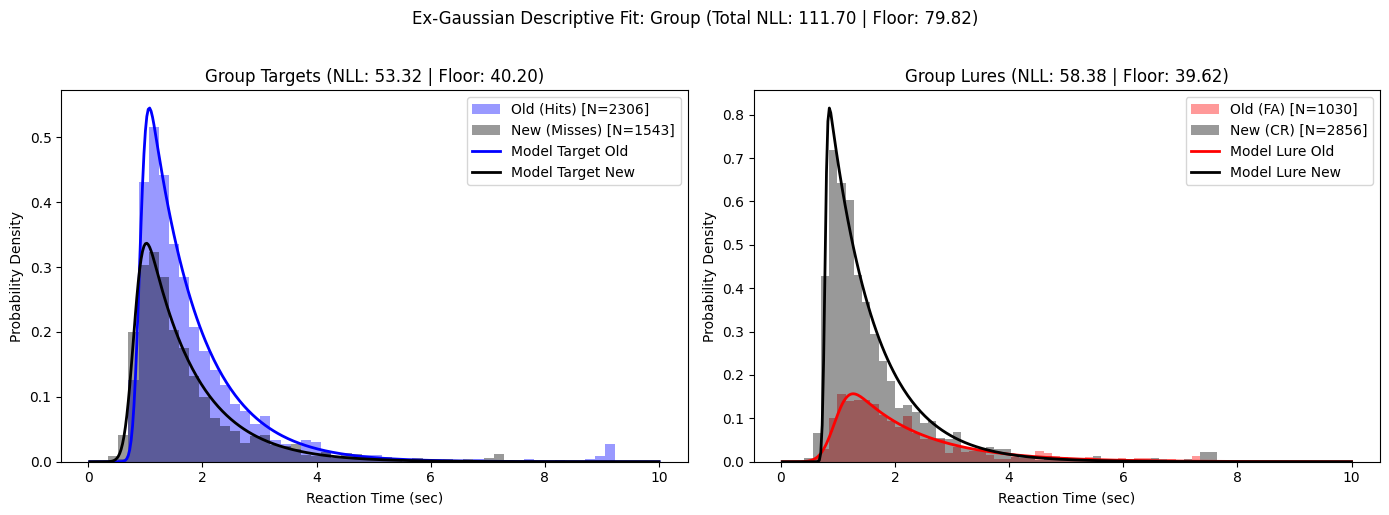


 INITIALIZING DESCRIPTIVE ANALYSIS: Subject 1
Fitting 14-Parameter Descriptive Ex-Gaussian...
differential_evolution step 1: f(x)= 615.0291641485351
differential_evolution step 2: f(x)= 561.1506860543959
differential_evolution step 3: f(x)= 561.1506860543959
differential_evolution step 4: f(x)= 561.1506860543959
differential_evolution step 5: f(x)= 523.4080883907473
differential_evolution step 6: f(x)= 457.64731426164826
differential_evolution step 7: f(x)= 457.64731426164826
differential_evolution step 8: f(x)= 457.64731426164826
differential_evolution step 9: f(x)= 457.64731426164826
differential_evolution step 10: f(x)= 457.64731426164826
differential_evolution step 11: f(x)= 407.1900004983063
differential_evolution step 12: f(x)= 353.6336908149683
differential_evolution step 13: f(x)= 315.0003358409408
differential_evolution step 14: f(x)= 288.40170531807235
differential_evolution step 15: f(x)= 288.40170531807235
differential_evolution step 16: f(x)= 271.1580951448459
differentia

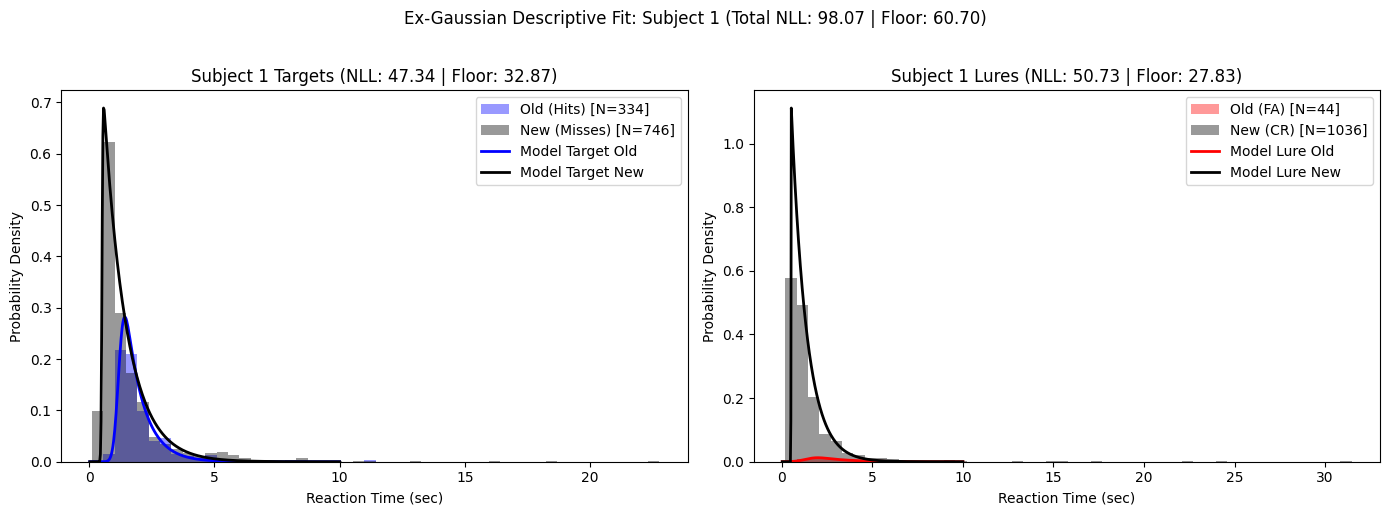


 INITIALIZING DESCRIPTIVE ANALYSIS: Subject 3
Fitting 14-Parameter Descriptive Ex-Gaussian...
differential_evolution step 1: f(x)= 1740.7527200836998
differential_evolution step 2: f(x)= 1678.0627712756777
differential_evolution step 3: f(x)= 1678.0627712756777
differential_evolution step 4: f(x)= 1525.9259284355853
differential_evolution step 5: f(x)= 1385.4444716827857
differential_evolution step 6: f(x)= 1385.4444716827857
differential_evolution step 7: f(x)= 1246.9666663324515
differential_evolution step 8: f(x)= 1196.2670325850381
differential_evolution step 9: f(x)= 1196.2670325850381
differential_evolution step 10: f(x)= 803.1939836130305
differential_evolution step 11: f(x)= 803.1939836130305
differential_evolution step 12: f(x)= 803.1939836130305
differential_evolution step 13: f(x)= 599.0616838036422
differential_evolution step 14: f(x)= 599.0616838036422
differential_evolution step 15: f(x)= 599.0616838036422
differential_evolution step 16: f(x)= 599.0616838036422
different

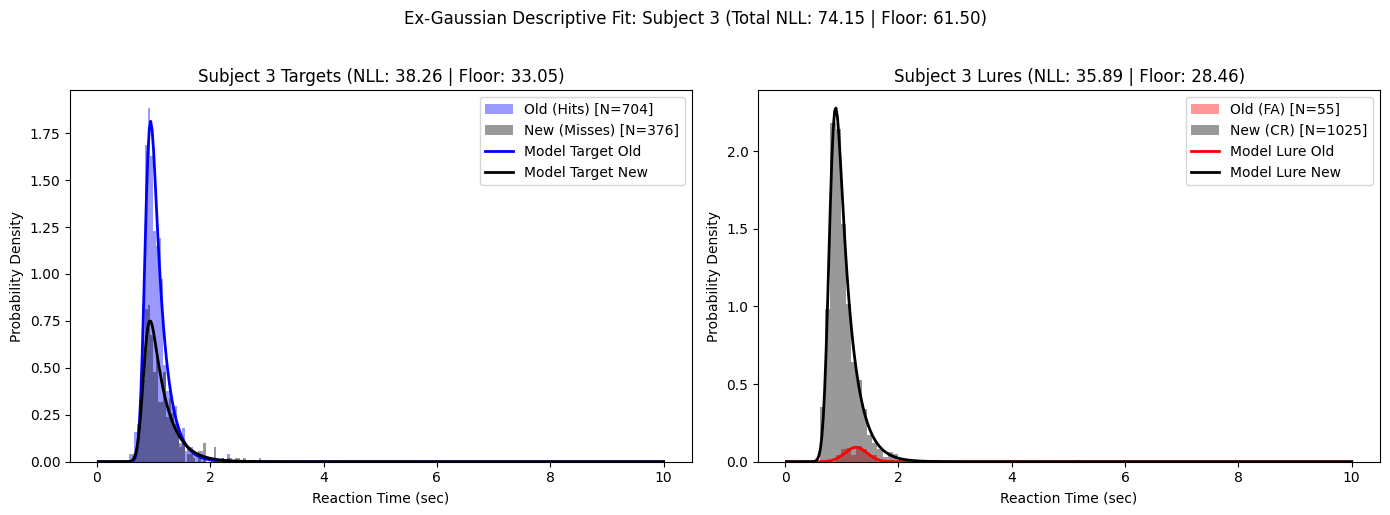


 INITIALIZING DESCRIPTIVE ANALYSIS: Subject 5
Fitting 14-Parameter Descriptive Ex-Gaussian...
differential_evolution step 1: f(x)= 865.6071141930342
differential_evolution step 2: f(x)= 830.8757102495288
differential_evolution step 3: f(x)= 830.8757102495288
differential_evolution step 4: f(x)= 636.8314090373351
differential_evolution step 5: f(x)= 636.8314090373351
differential_evolution step 6: f(x)= 636.8314090373351
differential_evolution step 7: f(x)= 373.22363668352955
differential_evolution step 8: f(x)= 373.22363668352955
differential_evolution step 9: f(x)= 373.22363668352955
differential_evolution step 10: f(x)= 373.22363668352955
differential_evolution step 11: f(x)= 373.22363668352955
differential_evolution step 12: f(x)= 373.22363668352955
differential_evolution step 13: f(x)= 373.22363668352955
differential_evolution step 14: f(x)= 373.22363668352955
differential_evolution step 15: f(x)= 373.22363668352955
differential_evolution step 16: f(x)= 373.22363668352955
differen

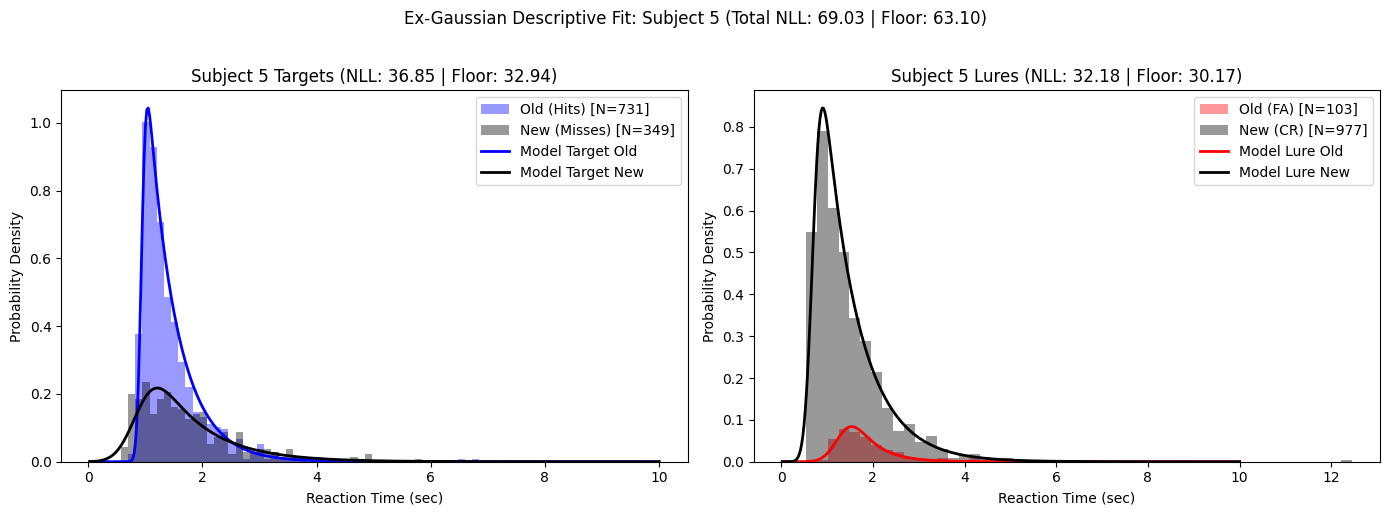


 INITIALIZING DESCRIPTIVE ANALYSIS: Subject 7
Fitting 14-Parameter Descriptive Ex-Gaussian...
differential_evolution step 1: f(x)= 1459.3536962788057
differential_evolution step 2: f(x)= 719.8235367854934
differential_evolution step 3: f(x)= 719.8235367854934
differential_evolution step 4: f(x)= 717.1914733780422
differential_evolution step 5: f(x)= 670.2827184177925
differential_evolution step 6: f(x)= 670.2827184177925
differential_evolution step 7: f(x)= 670.2827184177925
differential_evolution step 8: f(x)= 670.2827184177925
differential_evolution step 9: f(x)= 566.896768818925
differential_evolution step 10: f(x)= 566.896768818925
differential_evolution step 11: f(x)= 566.896768818925
differential_evolution step 12: f(x)= 566.896768818925
differential_evolution step 13: f(x)= 566.896768818925
differential_evolution step 14: f(x)= 566.896768818925
differential_evolution step 15: f(x)= 513.8557717369581
differential_evolution step 16: f(x)= 513.8557717369581
differential_evolution 

/home/mbh32/projects/research/caa_recognition_model/caa_model/models/base_model.py:151: RuntimeWarning: Maximum number of function evaluations has been exceeded.
  return minimize(



--- RESULTS FOR Subject 7 ---
 Absolute NLL Floor:   56.15 (Target: 33.00, Lure: 23.15)
 Ex-Gaussian Fit:      84.16 (Target: 46.49, Lure: 37.67)
 Total NLL Penalty:    28.01


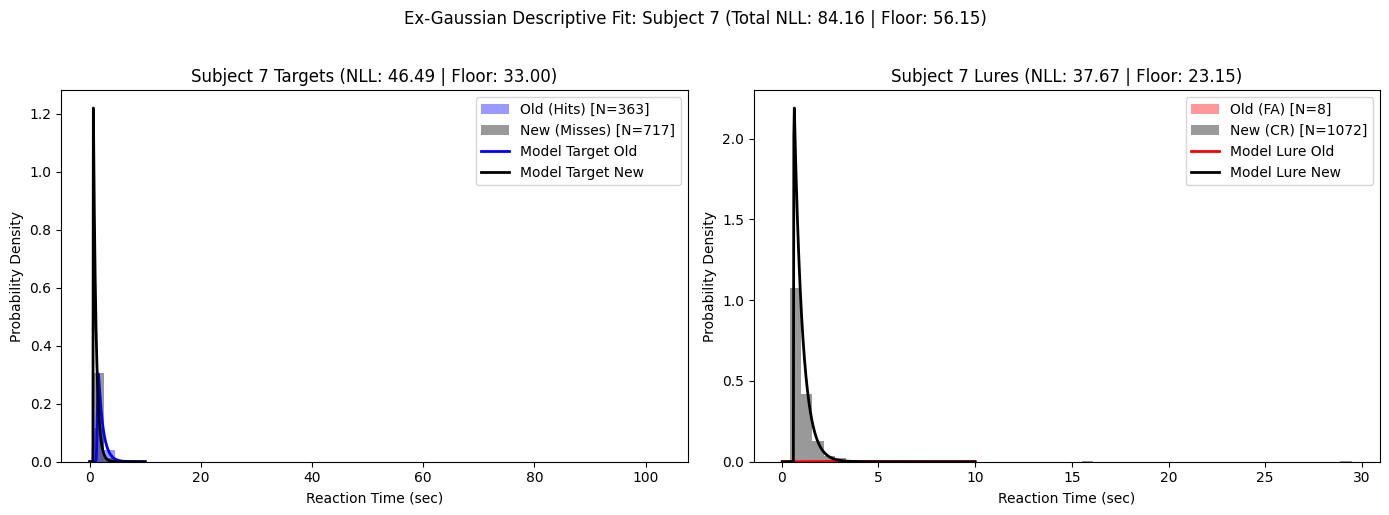

In [12]:
# --- DESCRIPTIVE EX-GAUSSIAN MODEL ---
class MacroscopicExGaussian(BaseDDM):
    """
    Fits descriptive Ex-Gaussian distributions directly to the RT data
    without simulating a physical accumulator.
    """
    class Params(NamedTuple):
        t_p_old: float
        t_mu_old: float
        t_sigma_old: float
        t_tau_old: float
        t_mu_new: float
        t_sigma_new: float
        t_tau_new: float

        l_p_old: float
        l_mu_old: float
        l_sigma_old: float
        l_tau_old: float
        l_mu_new: float
        l_sigma_new: float
        l_tau_new: float

    @staticmethod
    def split_params(model_params):
        t_p, t_mu_o, t_sig_o, t_tau_o, t_mu_n, t_sig_n, t_tau_n, \
        l_p, l_mu_o, l_sig_o, l_tau_o, l_mu_n, l_sig_n, l_tau_n = model_params

        return (t_p, t_mu_o, t_sig_o, t_tau_o, t_mu_n, t_sig_n, t_tau_n), \
               (l_p, l_mu_o, l_sig_o, l_tau_o, l_mu_n, l_sig_n, l_tau_n)

    def predicted_proportions(self, params):
        p_old_choice, mu_o, sig_o, tau_o, mu_n, sig_n, tau_n = params

        delta_t = self.config.delta_t
        t = pl.linspace(delta_t, self.config.max_t, self.config.nr_tsteps)

        # Prevent division by zero
        sig_o = max(sig_o, EPS)
        sig_n = max(sig_n, EPS)

        # Scipy exponnorm uses shape parameter K = tau / sigma
        K_o = max(tau_o / sig_o, EPS)
        K_n = max(tau_n / sig_n, EPS)

        # Generate the PDF and scale by the probability of the choice to get the mass
        p_old_mass = p_old_choice * stats.exponnorm.pdf(t, K_o, loc=mu_o, scale=sig_o) * delta_t
        p_new_mass = (1.0 - p_old_choice) * stats.exponnorm.pdf(t, K_n, loc=mu_n, scale=sig_n) * delta_t

        return p_old_mass, p_new_mass, t

    def compute_gof_all(self, model_params, data=None, method="qmpe", use_chisq=False):
        try:
            t_params, l_params = self.split_params(model_params)

            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            # Firmly locked at theoretical 2% lapse
            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t, lapse_rate=0.02)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t, lapse_rate=0.02)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical, p_predicted = [], []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0], emp_bounds[-1] = 0.0, pl.inf
                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1],
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x, p = pl.array(x_empirical), pl.array(p_predicted)
        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9
        return -multinom_loglike(x, N, pl.clip(p / p_sum, EPS, 1.0))

# --- EXECUTION WRAPPERS ---
def analyze_subject_exgauss(subject_id, config=caa_cfg):
    subject_id = str(subject_id).strip()
    print(f"\n==============================================")
    print(f" INITIALIZING DESCRIPTIVE ANALYSIS: Subject {subject_id}")
    print(f"==============================================")

    subj_data = get_subject_data(data_subject, subject_id)
    return _run_analysis(f"Subject {subject_id}", subj_data, config)

def analyze_group_exgauss(group_data, config=caa_cfg):
    print(f"\n==============================================")
    print(f" INITIALIZING DESCRIPTIVE ANALYSIS: Group")
    print(f"==============================================")

    return _run_analysis("Group", group_data, config)

def _run_analysis(label, dataset, config):
    t_old_rts = np.concatenate([dataset.rem_hit.rt, dataset.know_hit.rt])
    t_new_rts = dataset.miss.rt
    l_old_rts = np.concatenate([dataset.rem_fa.rt, dataset.know_fa.rt])
    l_new_rts = dataset.CR.rt
    N_target = len(t_old_rts) + len(t_new_rts)
    N_lure = len(l_old_rts) + len(l_new_rts)

    t_floor = get_saturated_qmpe_nll(t_old_rts, t_new_rts)
    l_floor = get_saturated_qmpe_nll(l_old_rts, l_new_rts)
    total_floor = t_floor + l_floor

    model = MacroscopicExGaussian(config=config)

    param_bounds = (
        MacroscopicExGaussian.Params(
            t_p_old=0.0, t_mu_old=0.0, t_sigma_old=EPS, t_tau_old=EPS, t_mu_new=0.0, t_sigma_new=EPS, t_tau_new=EPS,
            l_p_old=0.0, l_mu_old=0.0, l_sigma_old=EPS, l_tau_old=EPS, l_mu_new=0.0, l_sigma_new=EPS, l_tau_new=EPS
        ),
        MacroscopicExGaussian.Params(
            t_p_old=1.0, t_mu_old=2.0, t_sigma_old=2.0, t_tau_old=5.0, t_mu_new=2.0, t_sigma_new=2.0, t_tau_new=5.0,
            l_p_old=1.0, l_mu_old=2.0, l_sigma_old=2.0, l_tau_old=5.0, l_mu_new=2.0, l_sigma_new=2.0, l_tau_new=5.0
        )
    )

    print(f"Fitting 14-Parameter Descriptive Ex-Gaussian...")
    best_params = model.fit(param_bounds, data=dataset, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, data=dataset, method="qmpe")

    t_params, l_params = model.split_params(best_params)
    p_old_t, p_new_t, t = model.predicted_proportions(t_params)
    p_old_l, p_new_l, t = model.predicted_proportions(l_params)

    nll_target = model._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
    nll_lure = model._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

    print(f"\n--- RESULTS FOR {label} ---")
    print(f" Absolute NLL Floor:   {total_floor:.2f} (Target: {t_floor:.2f}, Lure: {l_floor:.2f})")
    print(f" Ex-Gaussian Fit:      {eval_result.nll:.2f} (Target: {nll_target:.2f}, Lure: {nll_lure:.2f})")
    print(f" Total NLL Penalty:    {eval_result.nll - total_floor:.2f}")

    # Plotting code remains identical (distributions plotting vs human histograms)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    delta_t = model.config.delta_t
    n_bins = 50

    t_min = min(np.min(t_old_rts), np.min(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 0
    t_max = max(np.max(t_old_rts), np.max(t_new_rts)) if len(t_old_rts)>0 or len(t_new_rts)>0 else 5
    t_edges = np.linspace(t_min, t_max, n_bins + 1)
    t_width = t_edges[1] - t_edges[0]

    if len(t_old_rts) > 0:
        w_t_old = np.ones_like(t_old_rts) / (N_target * t_width)
        axes[0].hist(t_old_rts, bins=t_edges, weights=w_t_old, alpha=0.4, color="blue", label=f"Old (Hits) [N={len(t_old_rts)}]")
    if len(t_new_rts) > 0:
        w_t_new = np.ones_like(t_new_rts) / (N_target * t_width)
        axes[0].hist(t_new_rts, bins=t_edges, weights=w_t_new, alpha=0.4, color="black", label=f"New (Misses) [N={len(t_new_rts)}]")

    axes[0].plot(t, p_old_t / delta_t, color="blue", lw=2, label="Model Target Old")
    axes[0].plot(t, p_new_t / delta_t, color="black", lw=2, label="Model Target New")
    axes[0].set_title(f"{label} Targets (NLL: {nll_target:.2f} | Floor: {t_floor:.2f})")
    axes[0].set_xlabel("Reaction Time (sec)")
    axes[0].set_ylabel("Probability Density")
    axes[0].legend()

    l_min = min(np.min(l_old_rts), np.min(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 0
    l_max = max(np.max(l_old_rts), np.max(l_new_rts)) if len(l_old_rts)>0 or len(l_new_rts)>0 else 5
    l_edges = np.linspace(l_min, l_max, n_bins + 1)
    l_width = l_edges[1] - l_edges[0]

    if len(l_old_rts) > 0:
        w_l_old = np.ones_like(l_old_rts) / (N_lure * l_width)
        axes[1].hist(l_old_rts, bins=l_edges, weights=w_l_old, alpha=0.4, color="red", label=f"Old (FA) [N={len(l_old_rts)}]")
    if len(l_new_rts) > 0:
        w_l_new = np.ones_like(l_new_rts) / (N_lure * l_width)
        axes[1].hist(l_new_rts, bins=l_edges, weights=w_l_new, alpha=0.4, color="black", label=f"New (CR) [N={len(l_new_rts)}]")

    axes[1].plot(t, p_old_l / delta_t, color="red", lw=2, label="Model Lure Old")
    axes[1].plot(t, p_new_l / delta_t, color="black", lw=2, label="Model Lure New")
    axes[1].set_title(f"{label} Lures (NLL: {nll_lure:.2f} | Floor: {l_floor:.2f})")
    axes[1].set_xlabel("Reaction Time (sec)")
    axes[1].set_ylabel("Probability Density")
    axes[1].legend()

    plt.suptitle(f"Ex-Gaussian Descriptive Fit: {label} (Total NLL: {eval_result.nll:.2f} | Floor: {total_floor:.2f})", y=1.02)
    plt.tight_layout()
    plt.show()

    return eval_result

if __name__ == "__main__":
    group_result = analyze_group_exgauss(data_group)

    subjects = ["1", "3", "5", "7"]
    results = {}
    for sub in subjects:
        results[sub] = analyze_subject_exgauss(sub)

### Diagnostic

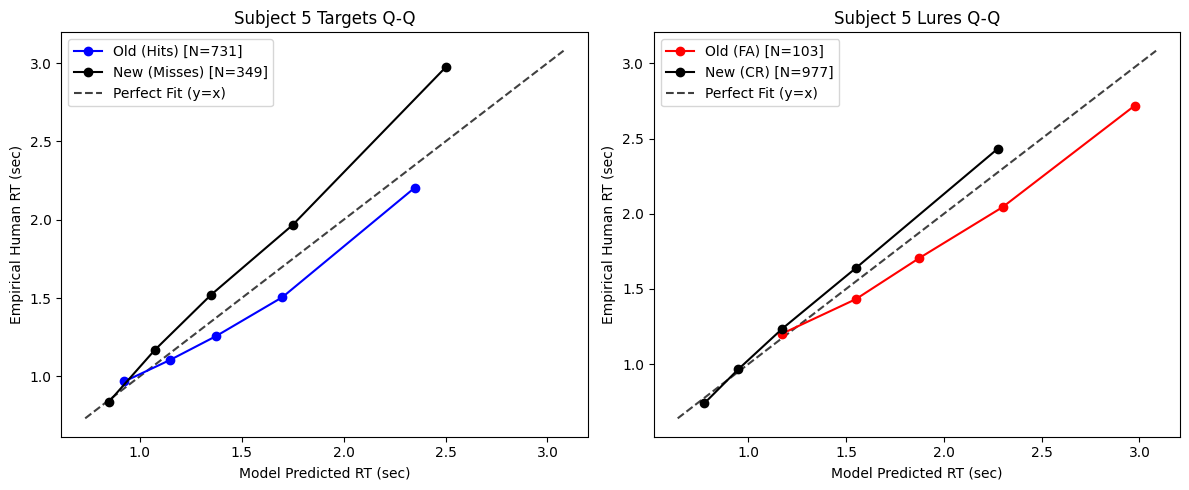

In [23]:
best_params = DriftVariabilityMacroscopicSISP.Params(mu_t=np.float64(0.7138862917580759), mu_l=np.float64(-0.4274437697204604), eta_t=np.float64(0.7973417729614627), eta_l=np.float64(0.030462504567972573), d_t=np.float64(0.2574864912455226), d_l=np.float64(0.2723416002724548), tc_bound=np.float64(0.2283822400905302), z0_t=np.float64(-0.19524500458536898), z0_l=np.float64(-0.335136472795578), t0=np.float64(0.559135492105655))

subject = "5"

model = DriftVariabilityMacroscopicSISP(config=caa_cfg)
subj5_data = get_subject_data(data_subject, subject)
generate_qq_plots(model, best_params, subj5_data, label=f"Subject {subject}")